# 04 · EMT-TF Expression — Wu et al. 2020 AML (unconditional final step)

The EMT-TF readout is produced regardless of gate outcomes; with Gate 2 GO (non-branching) / Gate 3 NA
this is the final notebook (**04**), and the branching-only `correlation`/`modules` notebooks are not
produced (§6). Score a widened mesenchymal-TF panel (Snail/Zeb/Twist **plus** FOXC/PRRX families, per
the Kurten lesson) **gated on detectable expression** — myeloid EMT-TFs are sparse — and read the
factor best marking each pseudotime end. The overlay is the reference **categorical** style: thresholded
expressers colored on a grey manifold (upper-quartile-of-positive cutoff), **not** a continuous colormap,
with marker size matched to the other panels. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 0; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Wu2020_Hematologic-2 | category: Hematologic


In [3]:
# read processed.h5ad per the spec I/O table (expression reads processed), but we need the
# pseudotime + house layout computed downstream -> load signatures.h5ad (superset of processed,
# same cells) and use its stored t / X_umap_lin.
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(float(t.min()),2), '->', round(float(t.max()),2))

cells: 96875 | pseudotime range 0.0 -> 6.75


### Derive the EMT-TF readout — detection-gated
Score genuine mesenchymal EMT transcription factors only (Snail/Zeb/Twist plus the FOXC/PRRX families
added per the Kurten lesson) — **not** hematopoietic master regulators (SOX4/RUNX1/GATA2), which are
abundant here but are a different program. Rank by detectable fraction and keep those above a sparse
floor. In this AML manifold the canonical EMT-TF panel is **largely silent** (expected for a myeloid
malignancy): only **ZEB2** is meaningfully expressed (~5%), with SNAI3/ZEB1 trailing near the floor and
**no pseudotime polarity** (all |rho|<0.02). We therefore show the top detectably-expressed EMT-TFs by
fraction (data-driven), which honestly reports the program as present-but-sparse and axis-agnostic.

In [4]:
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),4), round(x[early].mean(),4), round(x[late].mean(),4), round(rho,4)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
FLOOR = 0.005   # detectable-expression floor (myeloid EMT-TFs are very sparse)
ok = df[df.frac_expr > FLOOR].sort_values('frac_expr', ascending=False)
print(f'\ndetectably-expressed EMT-TFs (frac_expr > {FLOOR}):', list(ok.TF))
shown = list(ok.TF[:2]) if len(ok) >= 2 else list(ok.TF[:1])
print('EMT-TFs to display (top by detectable fraction):', shown)

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2     0.0513      0.0330     0.0346   -0.0104 LATE(terminus)
 SNAI3     0.0091      0.0056     0.0060   -0.0020 LATE(terminus)
  ZEB1     0.0050      0.0034     0.0033   -0.0051    EARLY(root)
TWIST2     0.0002      0.0002     0.0001    0.0015    EARLY(root)
 SNAI1     0.0001      0.0001     0.0000   -0.0020    EARLY(root)

detectably-expressed EMT-TFs (frac_expr > 0.005): ['ZEB2', 'SNAI3']
EMT-TFs to display (top by detectable fraction): ['ZEB2', 'SNAI3']


### Categorical thresholded-expresser overlay on grey manifold
Thresholded expressers (upper quartile of positive cells) colored over the grey manifold — the
reference categorical style, marker size matched to the signature panels, not a continuous colormap.

ZEB2: 5.1% expressing; 1241 shown (upper quartile of positives), mean pseudotime of shown = 0.59
SNAI3: 0.9% expressing; 220 shown (upper quartile of positives), mean pseudotime of shown = 0.61
EMT-TFs shown: ZEB2 + SNAI3 | saved expression.pdf


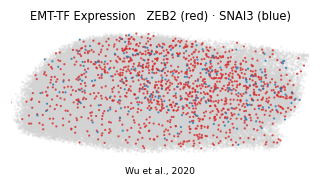

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
palette = ['tab:red','tab:blue','tab:green']
colors = {g: palette[i] for i,g in enumerate(shown)}
thr = {}
for g in shown:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in shown}
order = sorted(shown, key=lambda g: -int(sel[g].sum()))
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=8, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=8, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
lbl = ' · '.join(f'{g} ({colors[g].split(":")[1]})' for g in shown)
ax.set_title(f'EMT-TF Expression   {lbl}', size=7.5)
ax.text(.5,-.14,'Wu et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in shown:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile of positives), mean pseudotime of shown = {tn[m].mean():.2f}')
print('EMT-TFs shown:', ' + '.join(shown), '| saved expression.pdf')